In [224]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [225]:
df = pd.read_csv("Car_Data (1).csv")
df.head(n=10)

,Marque,Année,Boite_Vitesse,Adresse,Prix,Venant_Occasion
0,Mitsubishi,2017,Automatique,"Liberte 6,Dakar",9750000,Venant
1,Ford,2009,Manuelle,"Yoff,Dakar",2500000,D'occasion
2,BMW,2015,Automatique,"Cité Damel,Dakar",15500000,D'occasion
3,Ford,2013,Automatique,"Almadies,Dakar",3800000,D'occasion
4,GMC,2014,Automatique,"Hlm,Dakar",7500000,Venant
5,Mitsubishi,2014,Manuelle,"VDN,Dakar",13500000,Venant
6,Peugeot,2015,Automatique,"Yoff,Dakar",6000000,Venant
7,Porsche,2018,Automatique,"Plateau,Dakar",25000000,Venant
8,Kia,2012,Automatique,"Parcelles Assainies,Dakar",5700000,D'occasion
9,Ford,2013,Automatique,"Liberte 6 extension,Dakar",5800000,D'occasion


In [226]:
df.shape

(5507, 6)

**Description des variables**


Le jeu de données contient 5 507 annonces de véhicules décrites par 6 variables : 5 variables explicatives et 1 variable cible.
    
**Marque** : désigne le constructeur du véhicule (Ford, BMW, Mitsubishi, Peugeot, etc.). C'est une variable qualitative nominale.

**Année** : indique l'année de fabrication du véhicule. C'est une variable quantitative discrète.

**Boite_Vitesse** : précise le type de transmission du véhicule (automatique ou manuelle). C'est une variable qualitative nominale.

**Adresse** : représente la localisation géographique du véhicule à Dakar. C'est une variable qualitative nominale.

**Prix** : correspond au prix de vente du véhicule. C'est une variable quantitative.

**Venant_Occasion** : indique si le véhicule est venant ou d'occasion. C'est une variable qualitative nominale binaire qui constitue notre variable cible pour le problème de classification.

In [227]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5507 entries, 0 to 5506
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Marque           5507 non-null   str  
 1   Année            5507 non-null   int64
 2   Boite_Vitesse    5507 non-null   str  
 3   Adresse          5507 non-null   str  
 4   Prix             5507 non-null   int64
 5   Venant_Occasion  5507 non-null   str  
dtypes: int64(2), str(4)
memory usage: 258.3 KB


In [228]:
df.isnull().sum()

Marque             0
Année              0
Boite_Vitesse      0
Adresse            0
Prix               0
Venant_Occasion    0
dtype: int64

In [229]:
df.duplicated().sum()

np.int64(1094)

In [230]:
nb_doublons = df.duplicated().sum()
pourcentage = (nb_doublons / len(df)) * 100

print("Nombre de doublons :", nb_doublons)
print("Pourcentage :", pourcentage, "%")

Nombre de doublons : 1094
Pourcentage : 19.865625567459595 %


In [231]:
df.drop_duplicates(inplace=True)


In [232]:
df.duplicated().sum()

np.int64(0)

**Valeurs manquantes**

Aucune valeur manquante (NA) n'a été détectée dans le jeu de données.

**Valeurs dupliquées**
Le jeu de données contenait 1 094 doublons sur 5 507 observations, soit environ 19,86 %. Ces doublons ont été supprimés afin d'éviter la répétition des mêmes observations.

# Exploration et preparation des données

## Selection des variables catégorielles et quantitatives

In [233]:
# selection les variables catégorielles
df.select_dtypes(include='object').columns
# df.select_dtypes(exclude='number').columns

C:\Users\Fatou Ndiaye\AppData\Local\Temp\ipykernel_40016\1095709696.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include='object').columns


Index(['Marque', 'Boite_Vitesse', 'Adresse', 'Venant_Occasion'], dtype='str')

In [234]:
cat_data = df.select_dtypes(include='object')
# cat_data = df.select_dtypes(include='object')
cat_data.head()

C:\Users\Fatou Ndiaye\AppData\Local\Temp\ipykernel_40016\1483091070.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_data = df.select_dtypes(include='object')


,Marque,Boite_Vitesse,Adresse,Venant_Occasion
0,Mitsubishi,Automatique,"Liberte 6,Dakar",Venant
1,Ford,Manuelle,"Yoff,Dakar",D'occasion
2,BMW,Automatique,"Cité Damel,Dakar",D'occasion
3,Ford,Automatique,"Almadies,Dakar",D'occasion
4,GMC,Automatique,"Hlm,Dakar",Venant


In [235]:
# selection des variables quantitatives
df.select_dtypes(include='object').columns
# df.select_dtypes(include='number').columns
df.describe().columns

C:\Users\Fatou Ndiaye\AppData\Local\Temp\ipykernel_40016\3215943139.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include='object').columns


Index(['Année', 'Prix'], dtype='str')

In [236]:
quant_data = df.select_dtypes(include='number')
quant_data.head()

,Année,Prix
0,2017,9750000
1,2009,2500000
2,2015,15500000
3,2013,3800000
4,2014,7500000


## Exploration des variables catégorielles

In [237]:
# décrire les variables catégorielles
cat_data.describe(include='object')

C:\Users\Fatou Ndiaye\AppData\Local\Temp\ipykernel_40016\4025791075.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_data.describe(include='object')


,Marque,Boite_Vitesse,Adresse,Venant_Occasion
count,4413,4413,4413,4413
unique,46,3,182,2
top,Ford,Automatique,"Sacré-cœur,Dakar",D'occasion
freq,1072,3593,363,2216


In [238]:
# fonction de countplot
import plotly.express as px
def countplot_func(col):
  val = df[col].value_counts()
  fig = px.bar(x=val.index, y=val.values, color = val.index.astype(str), text_auto=True)
  fig.show()

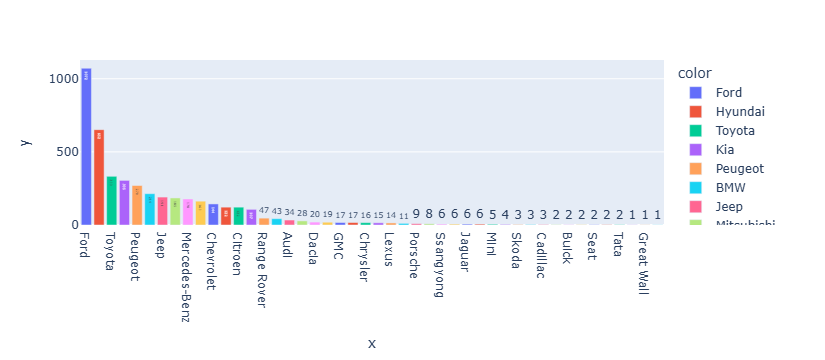

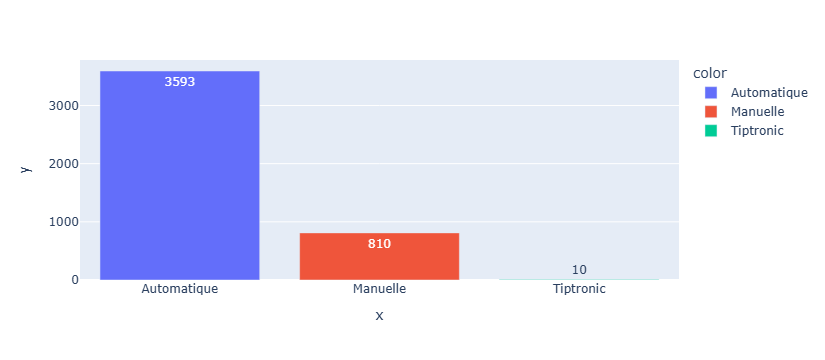

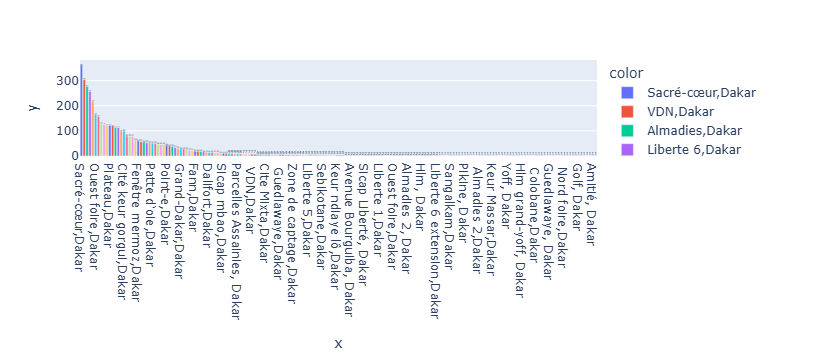

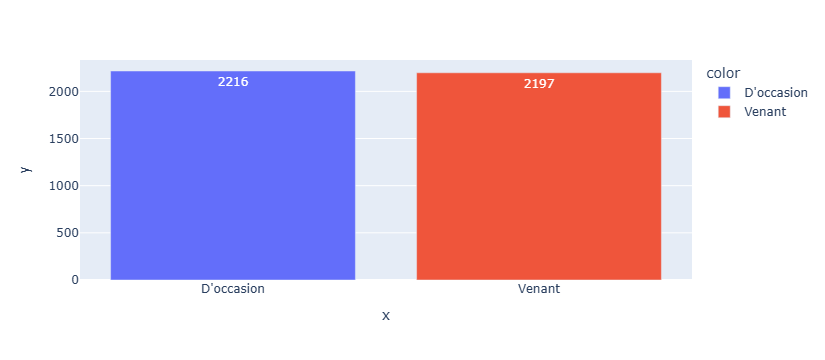

In [239]:
# Diagrammes en barre des variables catégorielles
for col in cat_data.columns:
  countplot_func(col)

## Conclusion

L'analyse des variables catégorielles montre que :

Les véhicules sont répartis entre 46 marques différentes, avec Ford comme marque la plus représentée.

La boîte de vitesse automatique est majoritaire.

L'adresse la plus fréquente est Sacré-Cœur, Dakar.


## Exploration des variables quantitatives

In [240]:
# décrire les variables quantitatives
quant_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Année,4413.0,2.014269e+03,3.215401e+00,1990.0,2013.0,2015.0,2016.0,2024.0
Prix,4413.0,1.052263e+07,1.704814e+07,1.0,4650000.0,7500000.0,12000000.0,779414131.0


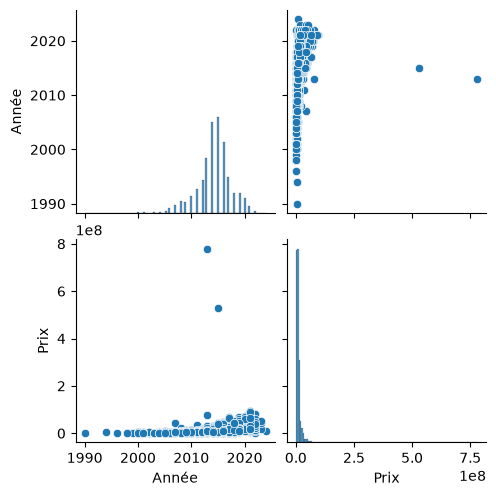

In [241]:
# pairplot des variables quantitatives
sns.pairplot(quant_data)
plt.show()

In [242]:
# matrice de correlation
quant_data.corr()

,Année,Prix
Année,1.0000,0.3293
Prix,0.3293,1.0000


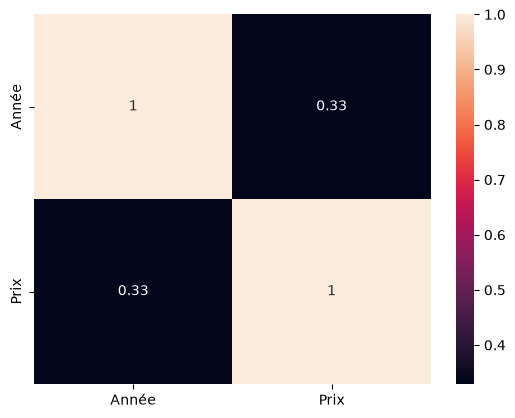

In [243]:
# heatmap  de la matrice de correlation
sns.heatmap(quant_data.corr(), annot = True)
plt.show()

## Conclusion

La matrice de corrélation montre une corrélation positive faible à modérée de 0,3293 entre l'année de fabrication et le prix du véhicule.

In [244]:
# fonction de visualisation des boxplots
def boxplot_func(col):
  plt.figure(figsize=(25,3))
  sns.boxplot(x=df[col])
  plt.show()

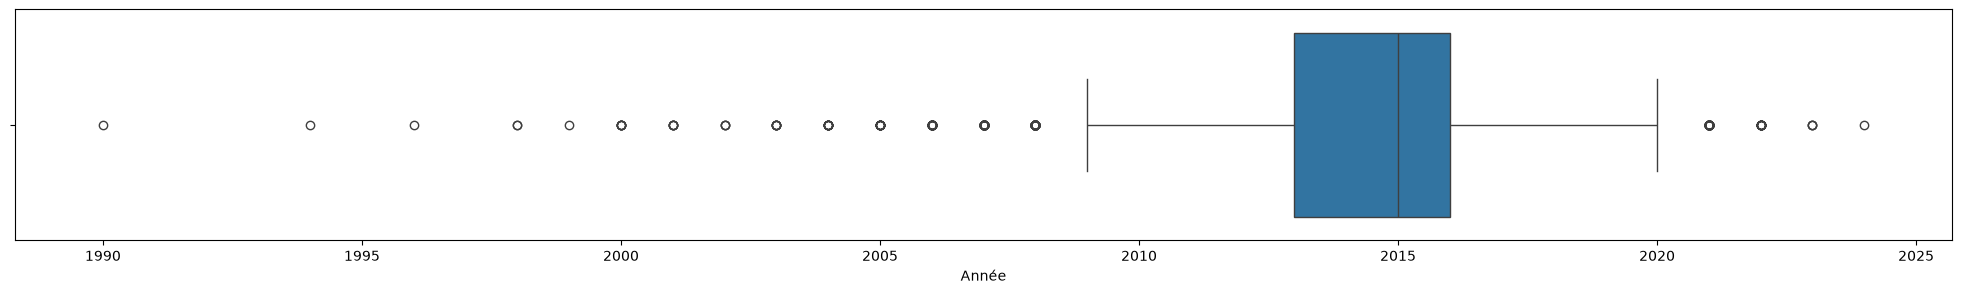

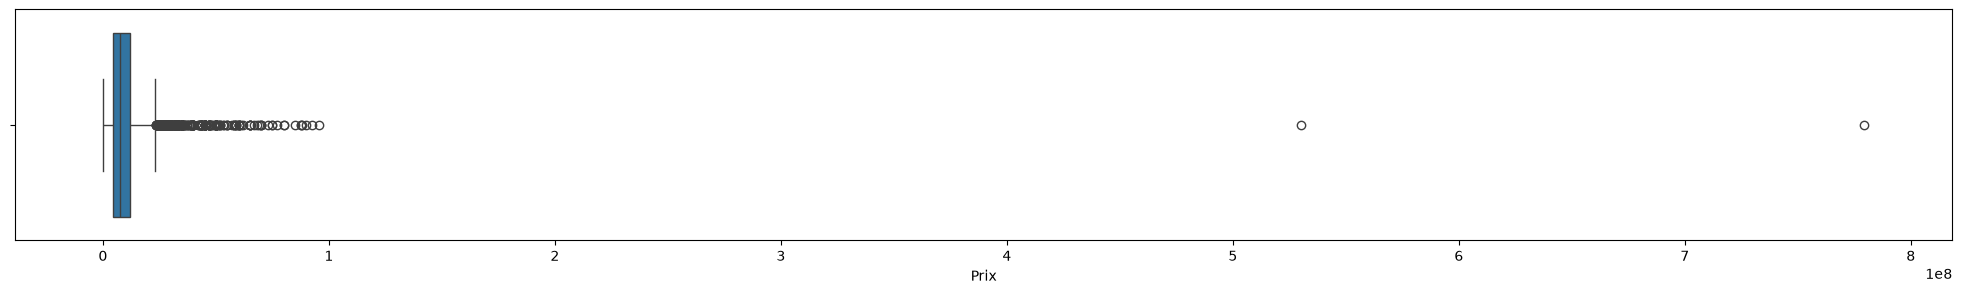

In [245]:
# boxplots des variables quantitatives
for col in quant_data.columns:
  boxplot_func(col)

In [246]:
print(df.sort_values('Prix', ascending=False).head(10))
print(df.sort_values('Prix').head(5))

             Marque  Année Boite_Vitesse            Adresse       Prix  \
4138            Kia   2013      Manuelle      Point-e,Dakar  779414131   
2803           Ford   2015   Automatique       Castor,Dakar  530000000   
4132  Mercedes-Benz   2021   Automatique   Sacré-cœur,Dakar   95500000   
1162  Mercedes-Benz   2021   Automatique   Sacré-cœur,Dakar   92500000   
5171  Mercedes-Benz   2021   Automatique    Liberte 6,Dakar   90000000   
3481  Mercedes-Benz   2021   Automatique    Liberte 6,Dakar   88000000   
2229  Mercedes-Benz   2021   Automatique   Sacré-cœur,Dakar   87500000   
3092  Mercedes-Benz   2021   Automatique   Sacré-cœur,Dakar   87500000   
4835  Mercedes-Benz   2021   Automatique         Yoff,Dakar   85000000   
978             BMW   2021   Automatique   Sacré-cœur,Dakar   80000000   

     Venant_Occasion  
4138      D'occasion  
2803          Venant  
4132          Venant  
1162          Venant  
5171          Venant  
3481          Venant  
2229          Venant  
3

In [247]:
# Supprimer les prix absurdes : trop bas (< 100 000) et trop hauts (> 200 millions)
df = df[(df['Prix'] >= 100000) & (df['Prix'] < 200000000)]
print(df.shape)

(4373, 6)


## Conclusion générale

J’ai gardé la colonne Année telle quelle : les voitures de 1990 ou de 2024 existent vraiment, ce ne sont pas des erreurs. Pour le Prix, j’ai supprimé les voitures vendues à moins de 100 000 FCFA, car ce sont des erreurs de saisie. J’ai aussi supprimé deux voitures à plus de 500 millions , car ce prix est impossible pour ces modèles. J’ai gardé les voitures de luxe à 80-95 millions, car ce sont de vrais prix.

## Preparation des données

In [278]:
# Enregistrer les valeurs uniques des variables catégorielles dans un objet joblib
uniques = []
for col in cat_data.columns:
  uniques.append(np.unique(df[col]).tolist())
# sauvegarde
import joblib as jb
jb.dump(uniques, 'uniques_clas2.joblib')

['uniques_clas2.joblib']

In [279]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder
# cette bibliotheque le fait selon l'ordre alphabetique
# Créer différents encodeurs pour les variables catégorielles
encoders = []
for i in range(len(cat_data.columns)):
  encoder = LabelEncoder()
  encoder.fit(df[cat_data.columns[i]]) # le modèle prend le temps de reconnaitre les classes
  df[cat_data.columns[i]] = encoder.transform(df[cat_data.columns[i]]) # encoder les valeurs
  # rajouter l'encoder sur la liste encoders
  encoders.append(encoder)

In [280]:
import joblib as jb
# sauvegarde les encodeurs
jb.dump(encoders, 'encoders_clas2.joblib')

['encoders_clas2.joblib']

In [281]:
df.head()

,Marque,Année,Boite_Vitesse,Adresse,Prix,Venant_Occasion
0,30,2017,0,117,9750000,1
1,13,2009,1,178,2500000,0
2,3,2015,0,55,15500000,0
3,13,2013,0,39,3800000,0
4,14,2014,0,99,7500000,1


In [252]:
# fonction de visualisation des boxplots
def boxplot_func(col):
  plt.figure(figsize=(25,3))
  sns.boxplot(x=df[col])
  plt.show()

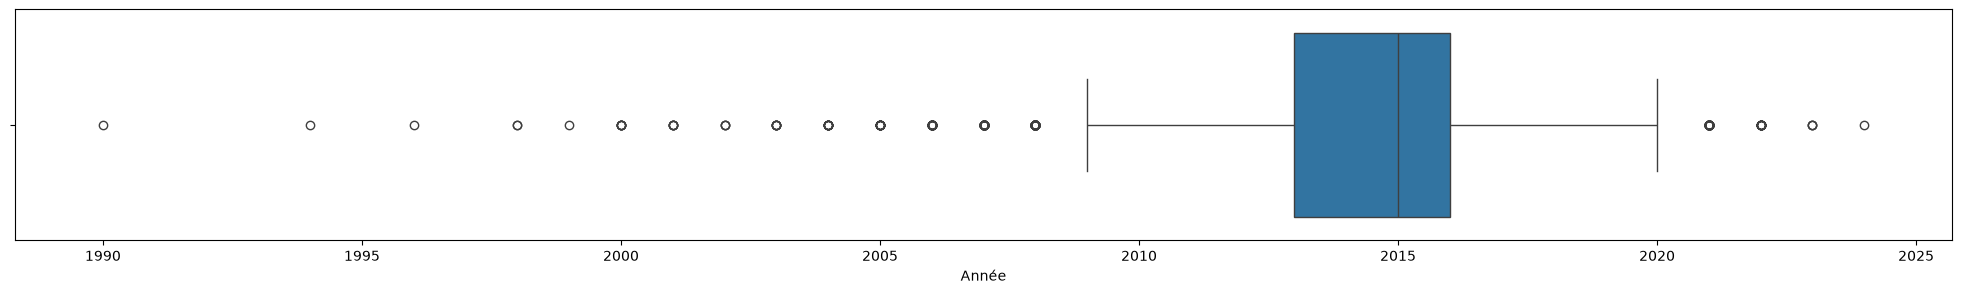

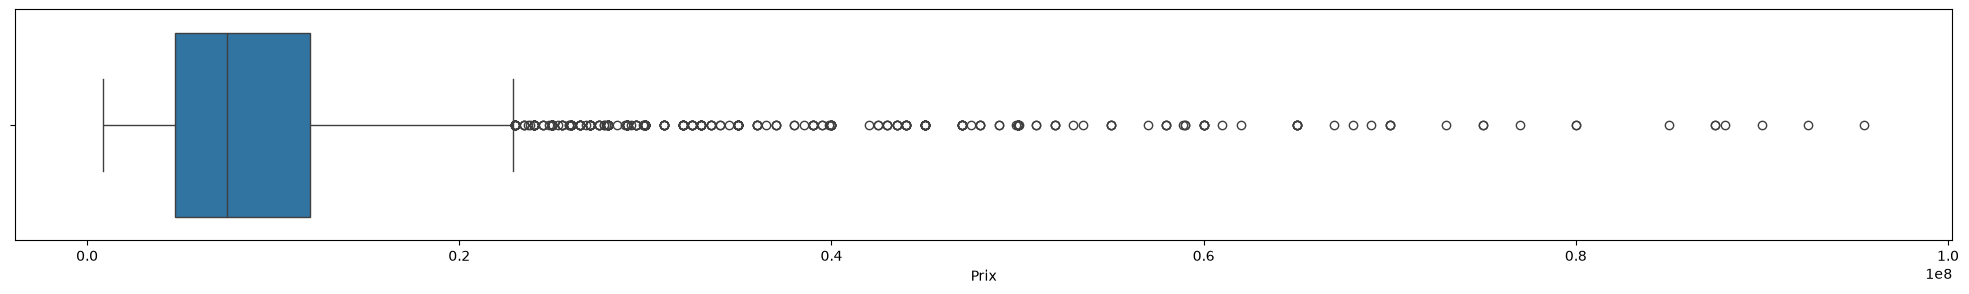

In [253]:
# boxplots des variables quantitatives
for col in quant_data.columns:
  boxplot_func(col)

## Conclusion

J’ai supprimé les prix qui n’étaient pas normaux : les voitures à 1 FCFA et les deux voitures à plus de 500 millions. Maintenant, les prix sont normaux. Je n’ai pas touché à l’année, car les voitures de 1990 à 2024 existent vraiment.

In [254]:
x = df.drop('Venant_Occasion', axis=1).values
y = df['Venant_Occasion'].values
x[:5], y[:5]

(array([[      30,     2017,        0,      117,  9750000],
        [      13,     2009,        1,      178,  2500000],
        [       3,     2015,        0,       55, 15500000],
        [      13,     2013,        0,       39,  3800000],
        [      14,     2014,        0,       99,  7500000]]),
 array([1, 0, 0, 0, 1]))

In [255]:
# normaliser les données
from sklearn.preprocessing import MinMaxScaler # Z = (X - Xmin)/(Xmax -Xmin)
scaler = MinMaxScaler()
x = scaler.fit_transform(x)
x[:5]

array([[0.66666667, 0.79411765, 0.        , 0.64640884, 0.09403064],
       [0.28888889, 0.55882353, 0.5       , 0.98342541, 0.01743265],
       [0.06666667, 0.73529412, 0.        , 0.3038674 , 0.15478077],
       [0.28888889, 0.67647059, 0.        , 0.21546961, 0.03116746],
       [0.31111111, 0.70588235, 0.        , 0.54696133, 0.07025885]])

In [282]:
# sauvegarde du scaler
jb.dump(scaler,'scaler_clas2.joblib')

['scaler_clas2.joblib']

In [283]:
# splitter les données en train, val et test
# train (80%), val(10%) et test(10%)
#train : données d'entrainement, val: données utiliser pour évaluer chaque et test: données pour tester le modèle le plus performant
from sklearn.model_selection import train_test_split
x_train, x_val_test, y_train, y_val_test = train_test_split(x, y, train_size= 0.8, random_state= 42)
x_val, x_test, y_val, y_test = train_test_split(x_val_test, y_val_test, train_size= 0.5, random_state= 42)


# Logistic Regression

## Recherche des paramètre optimaux

In [258]:
import numpy as np
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import LogisticRegression

cv = KFold(n_splits=5, shuffle=True, random_state=42)
params = {"C": np.logspace(-3, 3, 10), "l1_ratio": [0, 1]}

lg = LogisticRegression(solver='saga', max_iter=5000)
grid = GridSearchCV(lg, params, cv=cv, scoring='accuracy')
grid.fit(x_train, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...solver='saga')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': array([1.0000...00000000e+03]), 'l1_ratio': [0, 1]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Cont

In [259]:
# Afficher les paramètres optimaux
grid.best_params_

{'C': np.float64(0.46415888336127775), 'l1_ratio': 0}

## Entrainement du modèle

In [260]:
# Récupérer le modèle optimal en partant de gridsearch
lg_model = grid.best_estimator_

In [261]:
# fonction d'évaluation
from sklearn.metrics import f1_score, accuracy_score
def evaluation(model):
  y_pred = model.predict(x_val)
  acc = accuracy_score(y_val, y_pred)
  f1 = f1_score(y_val, y_pred, average='micro')
  return acc, f1

In [262]:
# Accuracy et F1 score du modèle sur les données de validation
acc_lg, f1_lg = evaluation(lg_model)
print(f"Accuracy : {acc_lg} --- F1 score : {f1_lg}")

Accuracy : 0.7231121281464531 --- F1 score : 0.7231121281464531


In [263]:
# Importer ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# y_pred:  prédictions du modèle sur les données validation
def CM_visualisation(model_objet):

    y_pred = model_objet.predict(x_val)
    # Confusion matrix
    cnf_matr = confusion_matrix(y_val, y_pred, labels=[0,1,2,3])

    # Utiliser ConfusionMatrixDisplay pour visualiser la matrice de confusion
    disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr,
                                  display_labels=['Occasion','Neuf', 'Reconditionné','Venant'])
    disp.plot() # Afficher la matrice de confusion
    plt.title('Matrice de confusion') # Définir le titre
    plt.show() # Afficher la figur

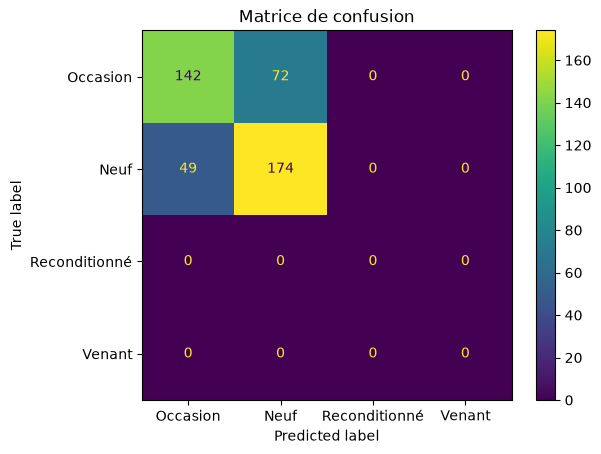

In [264]:
# Matrice de confusion
CM_visualisation(lg_model)

## Decision Tree

Recherche des paramètre optimaux

In [265]:
# Recherche des paramètres optimaux pour le Decision Tree
from sklearn.tree import DecisionTreeClassifier
# dictionnaire des params
param__ = {'criterion':['gini','entropy'],'max_depth':np.arange(3,15)}
# instantier le modèle Decision Tree
dt = DecisionTreeClassifier()
# instantier le modèle gridsearch
grid__ = GridSearchCV(dt, param__, cv = cv)
# entrainer le modèle
grid__.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': array([ 3, 4..., 12, 13, 14])}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, defa

In [266]:
# afficher les paramètres optimaux
grid__.best_params_

{'criterion': 'gini', 'max_depth': np.int64(4)}

## Entrainement du modèle

In [267]:
# Récupérer le modèle optimal en partant de gridsearch
dt_model = grid__.best_estimator_

In [268]:
# Accuracy et F1 score du modèle sur les données de validation
acc_dt, f1_dt = evaluation(dt_model)
print(f"Accuracy : {acc_dt} --- F1 score : {f1_dt}")

Accuracy : 0.7620137299771167 --- F1 score : 0.7620137299771167


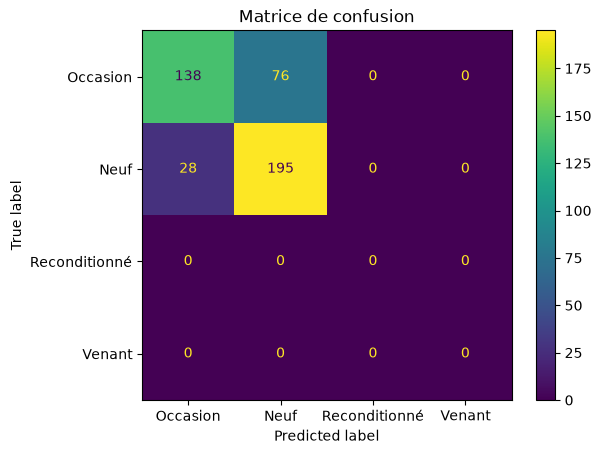

In [269]:
# Matrice de confusion
CM_visualisation(dt_model)

## Random Forest

In [270]:
# Recherche des paramètres optimaux pour le Random Forest
from sklearn.ensemble import RandomForestClassifier
# dictionnaire des  params
params = param_grid = {
    'n_estimators': list(np.arange(10,100,10)),
    'max_depth' : list(np.arange(3,15)),
    'criterion' :['gini', 'entropy']
}
# instantier le modèle Random Forest
rf = RandomForestClassifier()
# instantier le modèle gridsearch
grid = GridSearchCV(estimator=rf, param_grid=params, cv= cv)
# entrainer le modèle
grid.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [np.int64(3), np.int64(4), ...], 'n_estimators': [np.int64(10), np.int64(20), ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support f

In [271]:
# Afficher les paramètres optimaux
grid.best_params_

{'criterion': 'gini', 'max_depth': np.int64(8), 'n_estimators': np.int64(90)}

In [272]:
# Récupérer le modèle optimal en partant de gridsearch
rf_model_clas2 = grid.best_estimator_

## Evaluation du Random Forest

In [273]:
# Accuracy et F1 score du modèle sur les données de validation
acc_rf, f1_rf = evaluation(rf_model_clas2)
print(f"Accuracy : {acc_rf} --- F1 score : {f1_rf}")

Accuracy : 0.7688787185354691 --- F1 score : 0.7688787185354691


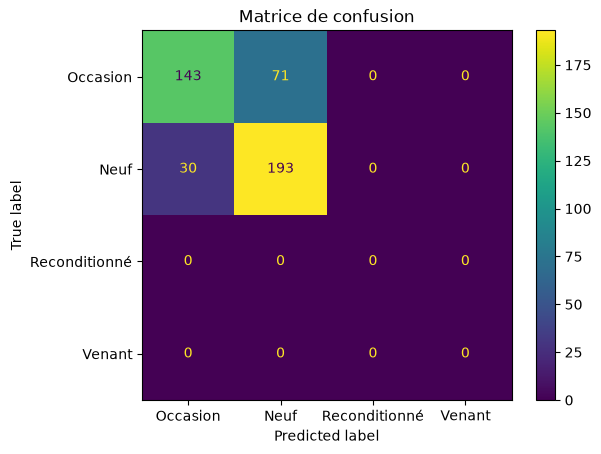

In [274]:
# Matrice de confusion
CM_visualisation(rf_model_clas2)

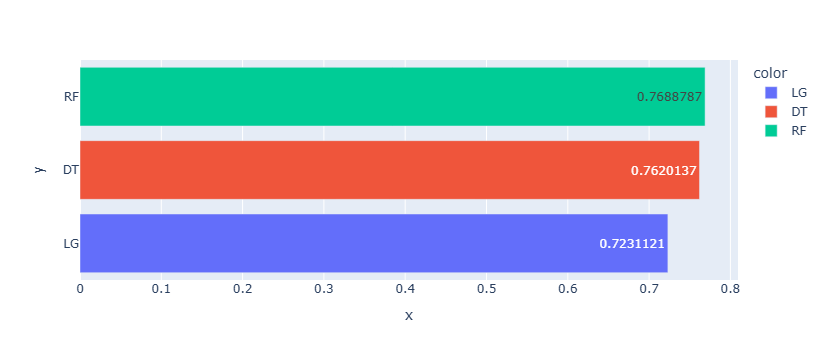

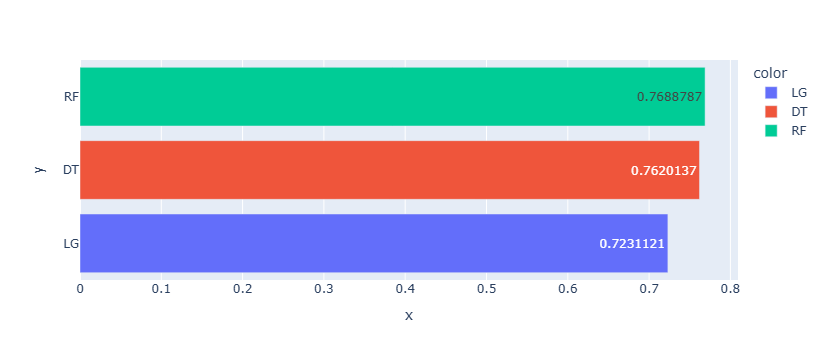

In [275]:
# diagramme des peformances
list_names = ['LG', 'DT', 'RF']
list_acc = [acc_lg, acc_dt, acc_rf]
list_f1 = [f1_lg, f1_dt, f1_rf]
list_final = [list_acc, list_f1]
for i in range(2):
  fig = px.bar(y=list_names, x = list_final[i], color = list_names, text_auto= True)
  fig.show()

In [276]:
# télécharger le modèle le plus performant
jb.dump(rf_model_clas2, 'rf_model_clas2.joblib')

['rf_model_clas2.joblib']

In [277]:
# echantillons
x_test_10 = x_test[:10]
y_test_10 = y_test[:10]
# predictions
y_pred_10 = rf_model.predict(x_test_10)
classnames = ['occasion', 'neuf', 'reconditionne', 'venant']
for i in range(10):
  print(f"prediction {str(i+1)} : {classnames[y_pred_10[i]]} -- {classnames[y_test_10[i]]}")

prediction 1 : neuf -- neuf
prediction 2 : neuf -- neuf
prediction 3 : neuf -- neuf
prediction 4 : occasion -- occasion
prediction 5 : neuf -- neuf
prediction 6 : neuf -- neuf
prediction 7 : occasion -- occasion
prediction 8 : occasion -- neuf
prediction 9 : neuf -- occasion
prediction 10 : occasion -- neuf


In [285]:
for i, encoder in enumerate(encoders):

    print("\nEncodeur :", i)

    print("Nombre de classes :", len(encoder.classes_))

    print("Premières classes :")
    print(encoder.classes_[:20])


Encodeur : 0
Nombre de classes : 46
Premières classes :
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]

Encodeur : 1
Nombre de classes : 3
Premières classes :
[0 1 2]

Encodeur : 2
Nombre de classes : 182
Premières classes :
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]

Encodeur : 3
Nombre de classes : 2
Premières classes :
[0 1]


In [286]:
print("Colonnes originales :")
print(df.columns.tolist())

print("\nAperçu des données :")
display(df.head(10))

Colonnes originales :
['Marque', 'Année', 'Boite_Vitesse', 'Adresse', 'Prix', 'Venant_Occasion']

Aperçu des données :


,Marque,Année,Boite_Vitesse,Adresse,Prix,Venant_Occasion
0,30,2017,0,117,9750000,1
1,13,2009,1,178,2500000,0
2,3,2015,0,55,15500000,0
3,13,2013,0,39,3800000,0
4,14,2014,0,99,7500000,1
5,30,2014,1,172,13500000,1
6,33,2015,0,178,6000000,1
7,34,2018,0,148,25000000,1
8,22,2012,0,140,5700000,0
9,13,2013,0,114,5800000,0


In [299]:
print("Type de Marque original :")
print(df["Marque"].dtype)

print("\nType de Marque encodé :")
print(df["Marque"].dtype)

Type de Marque original :
int64

Type de Marque encodé :
int64


In [302]:
import pandas as pd
import joblib

# Vérifier l'alignement des deux DataFrames
print("Taille cat_data :", len(cat_data))
print("Taille df :", len(df))

print("Index identiques :", df.index.isin(cat_data.index).all())

# Récupérer les lignes correspondantes
original = cat_data.loc[df.index]

# Construire les correspondances
colonnes = [
    "Marque",
    "Boite_Vitesse",
    "Adresse",
    "Venant_Occasion"
]

correspondances = {}

for colonne in colonnes:

    table = pd.DataFrame({
        "Original": original[colonne].astype(str),
        "Code": df[colonne].values
    })

    table = table.drop_duplicates()

    print("\nCorrespondances :", colonne)
    display(table.sort_values("Code"))

    # Vérifier qu'un nom correspond toujours au même code
    if table.groupby("Original")["Code"].nunique().max() > 1:
        raise ValueError(f"Correspondances incohérentes : {colonne}")

    correspondances[colonne] = dict(
        zip(table["Original"], table["Code"])
    )

# Sauvegarder les correspondances
joblib.dump(
    correspondances,
    "correspondances_clas2.joblib"
)

print("Correspondances sauvegardées !")

Taille cat_data : 4413
Taille df : 4373
Index identiques : True

Correspondances : Marque


,Original,Code
1359,Acura,0
59,Audi,1
2840,Autres,2
2,BMW,3
859,Buick,4
499,Cadillac,5
20,Chevrolet,6
372,Chrysler,7
83,Citroen,8
381,Dacia,9



Correspondances : Boite_Vitesse


,Original,Code
0,Automatique,0
1,Manuelle,1
271,Tiptronic,2



Correspondances : Adresse


,Original,Code
1359,"Almadies 2,Dakar",0
78,"Almadies,Dakar",1
1401,"Avenue Bourguiba,Dakar",2
5345,"Bambilor,Dakar",3
813,"Castor,Dakar",4
...,...,...
2394,"Yoff, Dakar",177
1,"Yoff,Dakar",178
2038,"Yoff,Dakar",179
170,"Zac Mbao,Dakar",180



Correspondances : Venant_Occasion


,Original,Code
1,D'occasion,0
0,Venant,1


Correspondances sauvegardées !
